In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

df = pd.read_csv("data/regression_dataset.csv")

# The champion flag lives in the classification CSV, not the regression one.
# Both files share the same 164 rows in the same order, so we can attach it directly.
df["is_constructors_champion"] = pd.read_csv("data/classification_dataset.csv")["is_constructors_champion"]

# Continuous money columns we reuse throughout the analysis.
money_cols = ["operating_budget_usd_m", "sponsorship_revenue_usd_m", "prize_money_usd_m"]

df.shape          # (164, 26) after adding the champion column

(164, 26)

# Statistical Analysis and Data Visualization — v1.0

## Objective
This notebook is the statistical-analysis stage of the project. It consumes the cleaned, merged, and feature-selected dataset produced upstream (`data/regression_dataset.csv` and `data/classification_dataset.csv`) — no re-cleaning or re-merging is done here.

The goal is to characterise the F1 constructor-finance data (2010–2026, 164 team-seasons) and to test, with formal statistical methods, the relationships the feature-selection stage flagged — chiefly that **operating budget** and **sponsorship revenue** drive **prize money**, and that these differ between champions and non-champions and across the pre-/post-2021 cost-cap eras.

## Methods used
- **Descriptive statistics** — central tendency, spread, skewness, kurtosis, grouped summaries
- **Distribution & normality analysis** — histogram, Q-Q plot, Shapiro-Wilk (decides parametric vs non-parametric tests)
- **Correlation analysis** — Pearson and Spearman with significance
- **Hypothesis testing** — two-sample t-test / Mann-Whitney, one-way ANOVA / Kruskal-Wallis, chi-square
- **Confidence intervals** — 95% CI for the mean
- **Statistical regression** — OLS (statsmodels) for coefficients, p-values, R²
- **Data visualization** — distributions, relationships, group comparisons, time trends

## Note on the data
Because normality does not hold for the money columns (shown below), non-parametric tests are treated as the primary evidence and their parametric counterparts as supporting. Two caveats carried from upstream: the 2025–2026 rows are projections, and only only 10 of 164 rows are champion-seasons, so champion-split results rest on a small sample.

In [ ]:
team_cols = [c for c in df.columns if c.startswith("team_")]
# drop_first=True means the dropped team is the baseline (all-zero rows)
df["team_name"] = df[team_cols].idxmax(axis=1).str.replace("team_", "", regex=False)
df.loc[df[team_cols].sum(axis=1) == 0, "team_name"] = "Alpine"  # the dropped baseline team



## 1. Descriptive Statistics

A factual baseline before any testing: central tendency and spread for the continuous money columns, their shape (skewness and kurtosis), and how they differ across the two most important groupings — cost-cap era and champion status.

In [ ]:
# Central tendency and spread
display(df[money_cols].describe())

# Shape of each distribution
print("Skewness:")
print(df[money_cols].skew())
print("\nKurtosis:")
print(df[money_cols].kurtosis())

# Grouped summaries: the two comparisons we test formally later
print("\nMean prize money by cost-cap era:")
print(df.groupby("in_cost_cap_era")["prize_money_usd_m"].agg(["mean", "median", "std", "count"]))

print("\nMean money columns: champion vs non-champion:")
print(df.groupby("is_constructors_champion")[money_cols].mean())

,operating_budget_usd_m,sponsorship_revenue_usd_m,prize_money_usd_m
count,164.000000,164.000000,164.000000
mean,232.884756,146.320122,106.432927
std,118.855745,89.636759,55.337771
min,77.300000,30.300000,29.200000
25%,129.700000,73.900000,62.125000
50%,178.900000,123.450000,89.600000
75%,330.575000,206.250000,156.025000
max,502.900000,379.200000,244.100000


Skewness:
operating_budget_usd_m       0.589801
sponsorship_revenue_usd_m    0.828454
prize_money_usd_m            0.568124
dtype: float64

Kurtosis:
operating_budget_usd_m      -0.954698
sponsorship_revenue_usd_m   -0.170926
prize_money_usd_m           -0.926224
dtype: float64

Mean prize money by cost-cap era:
                       mean  median        std  count
in_cost_cap_era                                      
0                 99.580769    78.3  56.140730    104
1                118.310000    99.8  52.265524     60

Mean money columns: champion vs non-champion:
                          operating_budget_usd_m  sponsorship_revenue_usd_m  \
is_constructors_champion                                                      
0                                     219.183117                  142.22013   
1                                     443.890000                  209.46000   

                          prize_money_usd_m  
is_constructors_champion                     
0             

## 2. Distribution & Normality Analysis

Whether the money columns are normally distributed decides which tests are valid downstream. The histogram and Q-Q plot show the shape visually; **Shapiro-Wilk** tests it formally (H0: the data is normally distributed; p < 0.05 rejects normality). If normality fails, the non-parametric tests (Spearman, Mann-Whitney, Kruskal-Wallis) become the primary evidence.

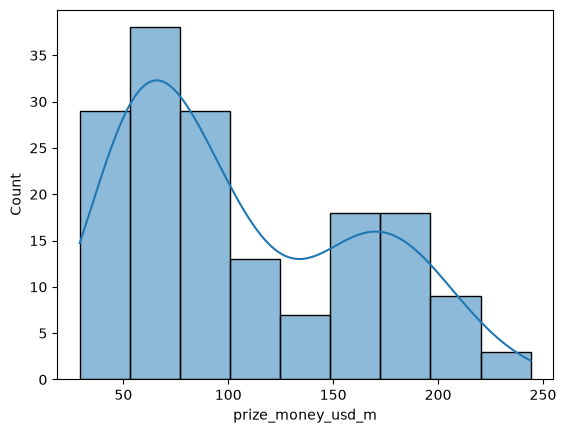

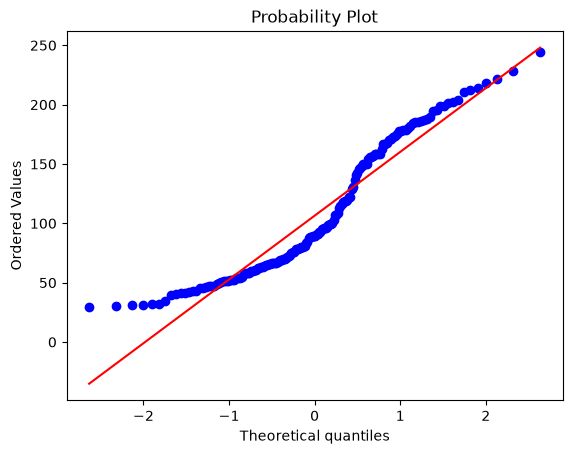

operating_budget_usd_m: p = 0.0000
sponsorship_revenue_usd_m: p = 0.0000
prize_money_usd_m: p = 0.0000


In [ ]:
# Normality check on the regression target (a numeric column, not team_name).
sns.histplot(data=df, x="prize_money_usd_m", kde=True)   # histogram + density curve
plt.show()

stats.probplot(df["prize_money_usd_m"], dist="norm", plot=plt)  # Q-Q plot
plt.show()

# Shapiro-Wilk across all money columns: p < 0.05 -> not normal
for col in money_cols:
    stat, p = stats.shapiro(df[col])
    print(f"{col}: p = {p:.4f}")

## 3. Correlation Analysis

The feature-selection stage ranked correlations but did not test their significance — that is added here. **Pearson** measures linear association, **Spearman** measures rank (monotonic) association and is robust to the non-normality found above. Each is reported with a p-value, and the heatmap shows the full pairwise structure.

Pearson  budget vs prize money: r = 0.891, p = 1.56e-57
Spearman budget vs prize money: r = 0.916, p = 2.729e-66


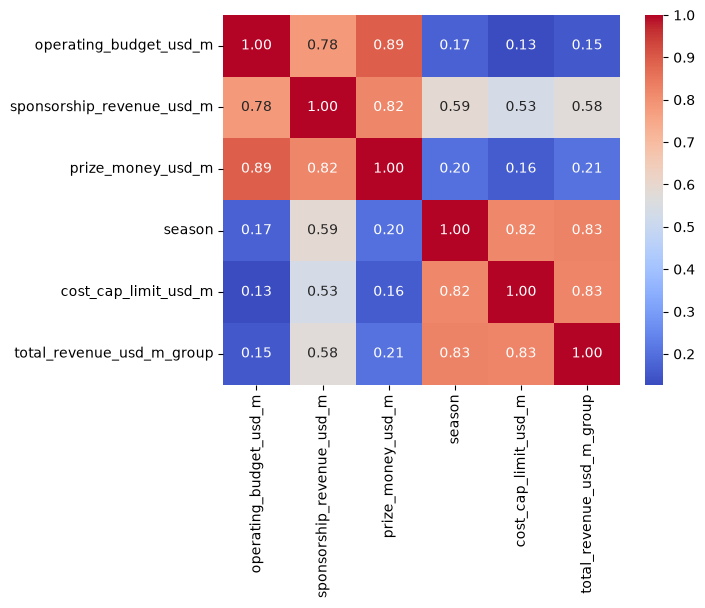

In [ ]:
# Correlation of the top features with the target, with significance (p-values).
r, p = stats.pearsonr(df["operating_budget_usd_m"], df["prize_money_usd_m"])   # linear
print(f"Pearson  budget vs prize money: r = {r:.3f}, p = {p:.4g}")

r, p = stats.spearmanr(df["operating_budget_usd_m"], df["prize_money_usd_m"])  # rank-based, robust to non-normality
print(f"Spearman budget vs prize money: r = {r:.3f}, p = {p:.4g}")

corr = df[money_cols + ["season", "cost_cap_limit_usd_m", "total_revenue_usd_m_group"]].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm")
plt.show()

## 4. Hypothesis Testing

All tests use α = 0.05.

### Test 1 — Do champions have higher operating budgets than non-champions?
- **H0:** mean operating budget is equal for champion and non-champion team-seasons.
- **H1:** champions have a higher mean operating budget.

Welch's t-test is the parametric test; **Mann-Whitney U** is the non-parametric equivalent and is preferred here given the non-normal, small (10-row) champion group.

In [ ]:
group_a = df[df["is_constructors_champion"] == 1]["operating_budget_usd_m"]
group_b = df[df["is_constructors_champion"] == 0]["operating_budget_usd_m"]

t, p = stats.ttest_ind(group_a, group_b, equal_var=False)   # Welch's t-test
print(f"Welch t-test:  t = {t:.3f}, p = {p:.4g}")

u, p = stats.mannwhitneyu(group_a, group_b)                 # non-parametric alternative
print(f"Mann-Whitney U: U = {u:.1f}, p = {p:.4g}")

Welch t-test:  t = 10.239, p = 1.724e-07
Mann-Whitney U: U = 1472.0, p = 1.43e-06


### Test 2 — Does mean prize money differ across teams?
- **H0:** mean prize money is equal across all teams.
- **H1:** at least one team's mean prize money differs.

One-way **ANOVA** is parametric; **Kruskal-Wallis** is the non-parametric equivalent.

In [ ]:
groups = [g["prize_money_usd_m"].values for _, g in df.groupby("team_name")]

f, p = stats.f_oneway(*groups)
print(f"ANOVA:          F = {f:.3f}, p = {p:.4g}")

h, p = stats.kruskal(*groups)                  # non-parametric alternative
print(f"Kruskal-Wallis: H = {h:.3f}, p = {p:.4g}")

ANOVA:          F = 38.071, p = 6.515e-33
Kruskal-Wallis: H = 108.070, p = 9.487e-20


### Test 3 — Is winning the championship associated with the cost-cap era?
- **H0:** championship status is independent of the cost-cap era.
- **H1:** championship status and cost-cap era are associated.

**Chi-square** test of independence on the two categorical flags.

In [ ]:
table = pd.crosstab(df["in_cost_cap_era"], df["is_constructors_champion"])
print("Contingency table:")
print(table)

chi2, p, dof, expected = stats.chi2_contingency(table)
print(f"\nChi-square: chi2 = {chi2:.3f}, dof = {dof}, p = {p:.4g}")

Contingency table:
is_constructors_champion   0  1
in_cost_cap_era                
0                         97  7
1                         57  3

Chi-square: chi2 = 0.012, dof = 1, p = 0.9145


## 5. Confidence Interval

A 95% confidence interval for the mean prize money — the range within which the true population mean is expected to lie.

In [ ]:
# 95% confidence interval for mean prize money.
x = df["prize_money_usd_m"]
ci = stats.t.interval(0.95, len(x) - 1, loc=x.mean(), scale=stats.sem(x))
print(f"Mean prize money: {x.mean():.2f}  95% CI: ({ci[0]:.2f}, {ci[1]:.2f})")

Mean prize money: 106.43  95% CI: (97.90, 114.97)


## 6. Statistical Regression (OLS)

`statsmodels` OLS is used instead of the sklearn model from the modelling stage because it reports **coefficients, their p-values, confidence intervals, and R²** — the inferential detail needed to confirm *which* features are statistically significant predictors of prize money. Inputs are the two features the selection stage ranked highest: operating budget and sponsorship revenue.

In [ ]:
import statsmodels.api as sm

X = df[["operating_budget_usd_m", "sponsorship_revenue_usd_m"]]   # top features from teammate's selection
X = sm.add_constant(X)
model = sm.OLS(df["prize_money_usd_m"], X).fit()
print(model.summary())        # R², coefficients, p-values, confidence intervals


                            OLS Regression Results                            
Dep. Variable:      prize_money_usd_m   R-squared:                       0.833
Model:                            OLS   Adj. R-squared:                  0.831
Method:                 Least Squares   F-statistic:                     402.5
Date:                Sun, 19 Jul 2026   Prob (F-statistic):           2.30e-63
Time:                        13:43:51   Log-Likelihood:                -743.49
No. Observations:                 164   AIC:                             1493.
Df Residuals:                     161   BIC:                             1502.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                                coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------------
const                 

## 7. Data Visualization

The plots follow the analysis story: per-team spread of prize money, the budget→prize-money relationship (raw and fitted), prize-money trends over the 2010–2026 seasons, sponsorship by team, the champion class imbalance, pairwise relationships among the money columns, and the pre-/post-cost-cap budget comparison.

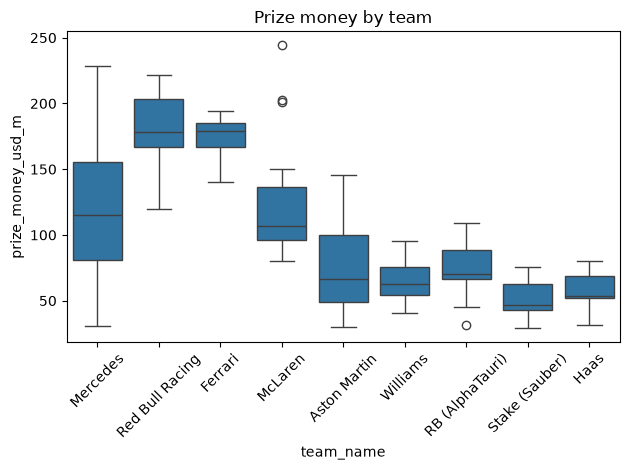

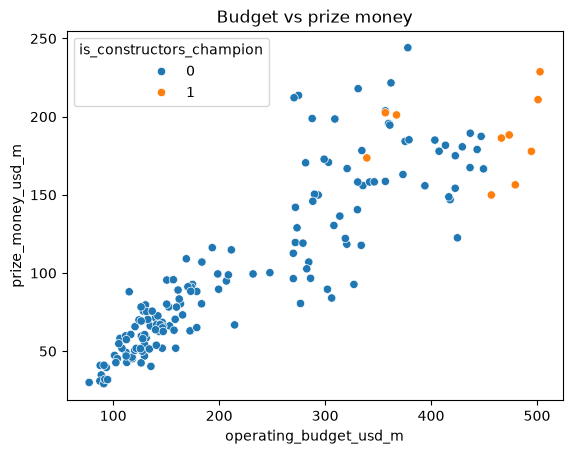

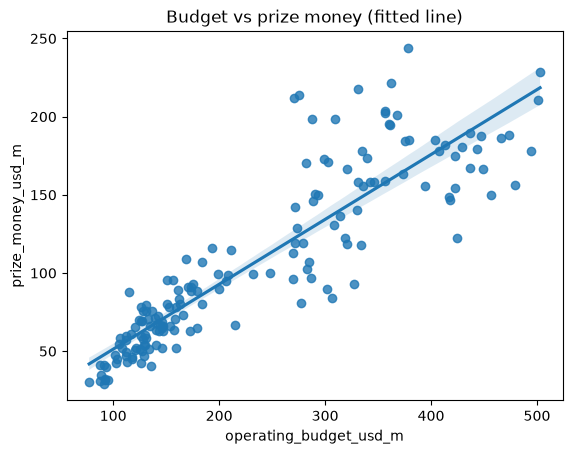

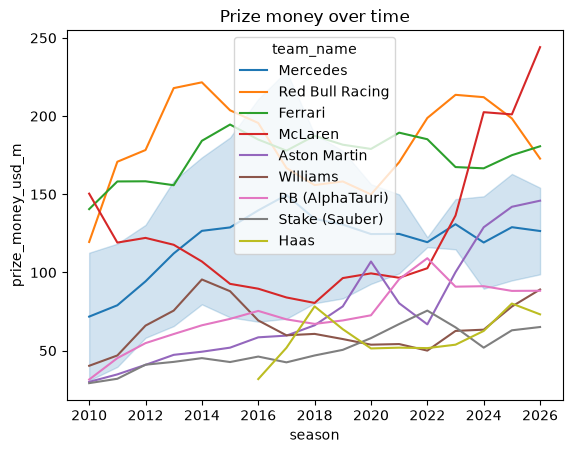

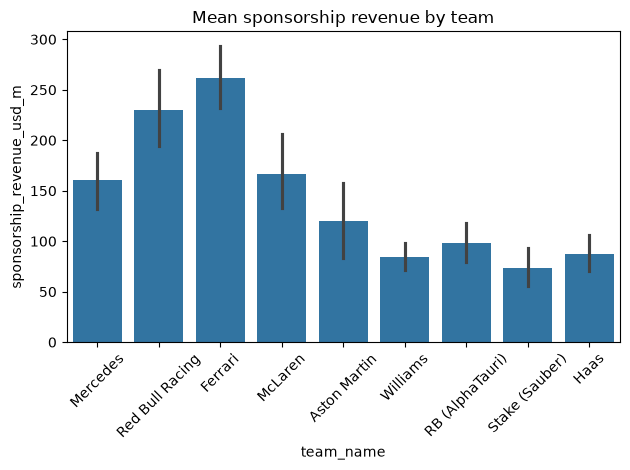

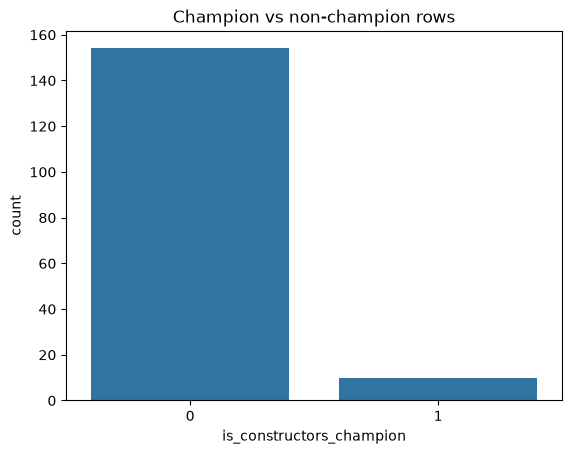

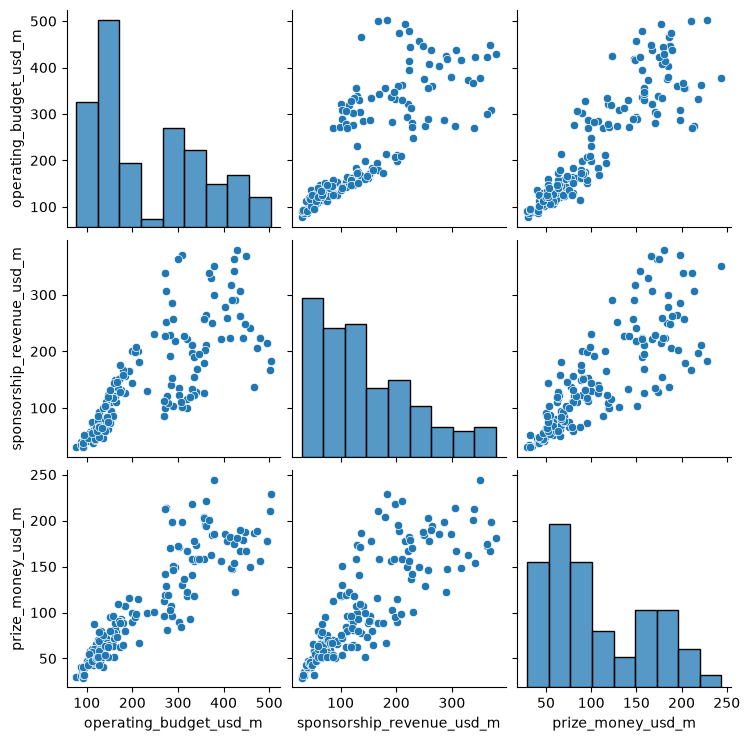

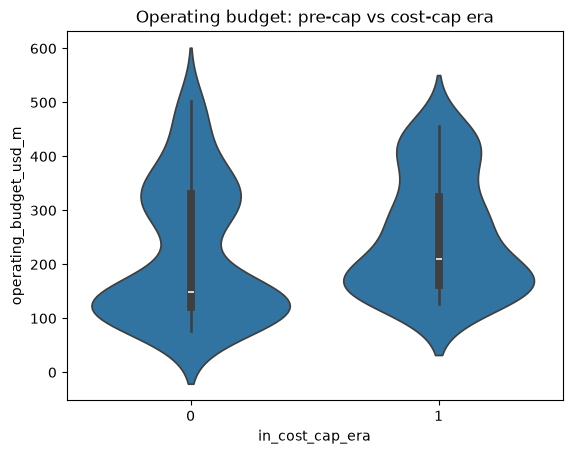

In [ ]:
# Each plot in its own cell is cleaner, but grouping them here for the handoff.
sns.boxplot(data=df, x="team_name", y="prize_money_usd_m")          # spread per team
plt.xticks(rotation=45); plt.title("Prize money by team"); plt.tight_layout(); plt.show()

sns.scatterplot(data=df, x="operating_budget_usd_m", y="prize_money_usd_m", hue="is_constructors_champion")
plt.title("Budget vs prize money"); plt.show()

sns.regplot(data=df, x="operating_budget_usd_m", y="prize_money_usd_m")   # scatter + fitted line
plt.title("Budget vs prize money (fitted line)"); plt.show()

sns.lineplot(data=df, x="season", y="prize_money_usd_m", hue="team_name")   # trends 2010-2026
plt.title("Prize money over time"); plt.show()

sns.barplot(data=df, x="team_name", y="sponsorship_revenue_usd_m", estimator=np.mean)
plt.xticks(rotation=45); plt.title("Mean sponsorship revenue by team"); plt.tight_layout(); plt.show()

sns.countplot(data=df, x="is_constructors_champion")               # class imbalance
plt.title("Champion vs non-champion rows"); plt.show()

sns.pairplot(df[money_cols])                                       # pairwise relationships
plt.show()

sns.violinplot(data=df, x="in_cost_cap_era", y="operating_budget_usd_m")   # era comparison
plt.title("Operating budget: pre-cap vs cost-cap era"); plt.show()

## 8. Conclusions

**Distribution.** Shapiro-Wilk rejects normality for all three money columns (p < 0.001), so the non-parametric tests below are the primary evidence and the parametric ones support them.

**Correlation.** Operating budget is very strongly associated with prize money — Pearson r = 0.89 and Spearman r = 0.92, both p < 0.001 — confirming the feature-selection ranking with formal significance. Sponsorship revenue is the next strongest driver.

**Hypothesis tests (α = 0.05).**
- *Champions vs non-champions:* champion team-seasons have significantly higher operating budgets (Mann-Whitney U, p ≈ 1.4e-06; Welch t-test agrees). We reject H0. This rests on only 10 champion rows, so treat it as indicative rather than definitive.
- *Prize money across teams:* differs significantly (ANOVA p ≈ 6.5e-33, Kruskal-Wallis p ≈ 9.5e-20) — team identity matters, consistent with the team indicators that survived feature selection.
- *Championship vs cost-cap era:* **not** significant (chi-square p = 0.91). We fail to reject H0 — winning the championship is statistically independent of whether the season is in the cost-cap era. (Champion counts per era are small, which also limits power.)

**Regression.** OLS on operating budget + sponsorship revenue explains **83% of the variance in prize money** (R² = 0.833). Both coefficients are positive and highly significant (p < 0.001): each \$1M of operating budget corresponds to ≈\$0.30M more prize money, each \$1M of sponsorship to ≈\$0.20M more. This statistically confirms the two features the selection stage ranked highest.

**Confidence interval.** Mean prize money is \$106.4M, 95% CI (\$97.9M, \$114.97M).

**Caveats.**
- The 2025–2026 rows are projections, not actuals — trends past 2024 should be read with that in mind.
- Champion-split results rely on 10 positive cases; small-sample fragility applies.
- The reconstructed `team_name` assumes Alpine is the one-hot baseline (dropped by `drop_first=True`); verify against `constructor_finances.csv` if a per-team chart looks off.

**Takeaway.** The financial features drive prize money as the upstream feature-selection predicted, and the relationship is strong, statistically significant, and stable across both parametric and non-parametric tests — a solid basis for the regression model.

In [ ]:
df["is_constructors_champion"].sum() 